In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pymatgen.core import IStructure, Lattice, Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pymatgen.analysis.diffraction.neutron  import NDCalculator

In [2]:
def split_lammps_trj(file_path, output_prefix="structure"):
    with open(file_path, 'r') as file:
        lines = file.readlines()
        
    structure_count = 0
    structure_data = []
    
    for line in lines:
        if line.startswith("ITEM: TIMESTEP"):
            if structure_data:
                # Write the collected structure data to a new file
                output_file = f"{output_prefix}_{structure_count}.trj"
                with open(output_file, 'w') as out_file:
                    out_file.writelines(structure_data)
                structure_data = []
                structure_count += 1
        structure_data.append(line)
    
    # Write the last structure data to a new file
    if structure_data:
        output_file = f"{output_prefix}_{structure_count}.trj"
        with open(output_file, 'w') as out_file:
            out_file.writelines(structure_data)

In [3]:
def calculate_angles(xy, xz, yz, a, b, c):
    # Calculate cosines of the angles
    cos_alpha = xy / (a * b)
    cos_beta = xz / (a * c)
    cos_gamma = yz / (b * c)
    
    # Calculate the angles in radians
    alpha = np.arccos(cos_alpha)
    beta = np.arccos(cos_beta)
    gamma = np.arccos(cos_gamma)
    
    # Convert to degrees
    alpha_deg = np.degrees(alpha)
    beta_deg = np.degrees(beta)
    gamma_deg = np.degrees(gamma)
    
    return alpha_deg, beta_deg, gamma_deg

In [4]:
def read_lammps_trj(file_path):
    """Reads a LAMMPS trajectory file and converts it to a pymatgen Structure object."""
    with open(file_path, 'r') as file:
        lines = file.readlines()

    # Read box bounds
    for i, line in enumerate(lines):
        if line.startswith("ITEM: BOX BOUNDS"):
            x_bounds = list(map(float, lines[i+1].split()))
            y_bounds = list(map(float, lines[i+2].split()))
            z_bounds = list(map(float, lines[i+3].split()))
            break

    # Calculate lattice vectors
    a = x_bounds[1] - x_bounds[0]
    b = y_bounds[1] - y_bounds[0]
    c = z_bounds[1] - z_bounds[0]
    alpha, beta, gamma = calculate_angles(x_bounds[2], y_bounds[2], z_bounds[2], a, b, c)
    lattice = Lattice.from_parameters(a, b, c, alpha, beta, gamma)

    # Define atom type mapping
    atom_type_map = {
        1: "C",
        2: "Mn2+",
        3: "Fe2+",
        4: "N",
        5: "Na+"
    }

    # Read atom positions
    atom_positions = []
    atom_species = []
    for i, line in enumerate(lines):
        if line.startswith("ITEM: ATOMS"):
            for atom_line in lines[i+1:]:
                atom_data = atom_line.split()
                atom_type = int(atom_data[1])
                species = atom_type_map[atom_type]
                x = float(atom_data[2])
                y = float(atom_data[3])
                z = float(atom_data[4])
                atom_positions.append([x, y, z])
                atom_species.append(species)
            break
    
    # Create pymatgen Structure object
    structure = IStructure(lattice, atom_species, atom_positions, coords_are_cartesian=True)
    return structure

In [5]:
def calculate_xrd(structure, wavelength="CuKa", output_file=None):
    """Calculates and saves the XRD pattern for a given pymatgen Structure object."""
    xrd_calculator = XRDCalculator(wavelength=wavelength, symprec=0)
    xrd_pattern = xrd_calculator.get_pattern(structure, two_theta_range=(10,40))
    
    if output_file:
        # Save the XRD pattern to a file
        with open(output_file, 'w') as f:
            for two_theta, intensity in zip(xrd_pattern.x, xrd_pattern.y):
                f.write(f"{two_theta:.2f} {intensity:.2f}\n")

    return xrd_pattern

In [6]:
def two_theta_to_q(two_theta, wavelength):
    theta = np.radians(two_theta / 2.0)
    q = (4.0 * np.pi * np.sin(theta)) / wavelength
    return q

# XRD

In [13]:
# Use the function
split_lammps_trj("dump.gcmc.trj")
! rm ./trj/structure*
! mv structure* trj

In [23]:
to_calculate = np.arange(0, len(os.listdir(trajectory_dir))-1, round(len(os.listdir(trajectory_dir))/10,0)).astype(int)

In [26]:
to_calculate.shape[0]

11

In [27]:
! rm ./xrd_patterns *xrd.dat
trajectory_dir = "./trj"
output_dir = "xrd_patterns"
os.makedirs(output_dir, exist_ok=True)

for i in range(to_calculate.shape[0]):
    file_name = f'structure_{to_calculate[i]}.trj'
    structure_file = os.path.join(trajectory_dir, file_name)
    
    # Read the structure from the trajectory file
    structure = read_lammps_trj(structure_file)
    
    # Calculate XRD pattern
    output_file = os.path.join(output_dir, f"{os.path.splitext(file_name)[0]}_xrd.dat")
    xrd_pattern = calculate_xrd(structure, output_file=output_file)
    
    print(f"XRD pattern calculated and saved for {file_name}")

XRD pattern calculated and saved for structure_0.trj
XRD pattern calculated and saved for structure_33.trj
XRD pattern calculated and saved for structure_66.trj
XRD pattern calculated and saved for structure_99.trj
XRD pattern calculated and saved for structure_132.trj
XRD pattern calculated and saved for structure_165.trj
XRD pattern calculated and saved for structure_198.trj
XRD pattern calculated and saved for structure_231.trj
XRD pattern calculated and saved for structure_264.trj
XRD pattern calculated and saved for structure_297.trj
XRD pattern calculated and saved for structure_330.trj


In [28]:
xrd_dir = "./xrd_patterns"
XRD_list=[]

for i in range(to_calculate.shape[0]):
    file_name = f'structure_{to_calculate[i]}_xrd.dat'
    file_path = os.path.join(xrd_dir, file_name)
    # Load the text file into a NumPy array
    try:
        # Adjust the delimiter and other parameters as needed
        array = np.loadtxt(file_path, delimiter=' ')  # Example delimiter
        XRD_list.append(array)
    except Exception as e:
        print(f"Error loading {file_path}: {e}")

In [45]:
XRD_list[1][:,1].argmax()

1254

In [47]:
two_theta_to_q(XRD_list[1][XRD_list[1][:,1].argmax(),0],1.54059)

1.3280125840093682

1.3280125840093682
1.3245008450401572
1.3167741326240803
1.3195839869937094
1.31817907988591
1.3125590503423823
1.3153691452510166
1.3076409996234755
1.311856501612577
1.304830465727622


(1.3, 1.35)

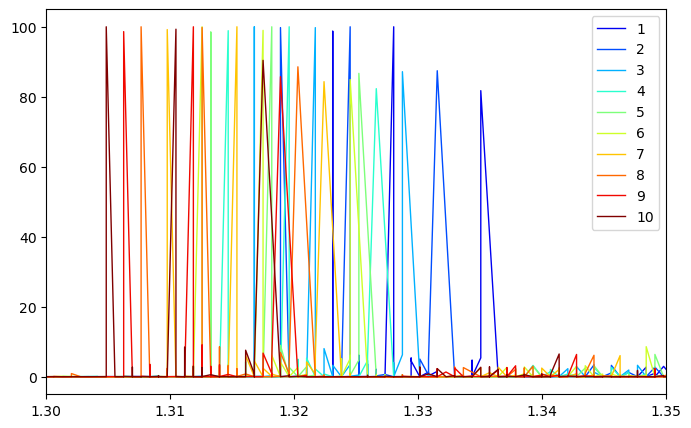

In [50]:
fig = plt.figure(figsize=(8,5))
colors = cm.jet(np.linspace(0, 1, to_calculate.shape[0]))
for i in range(1,to_calculate.shape[0]):
    x=XRD_list[i][:,0]
    q=two_theta_to_q(x, 1.54059)
    y=XRD_list[i][:,1]
    plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
    print(two_theta_to_q(XRD_list[i][XRD_list[i][:,1].argmax(),0],1.54059))
plt.legend()
plt.xlim(1.3,1.35)

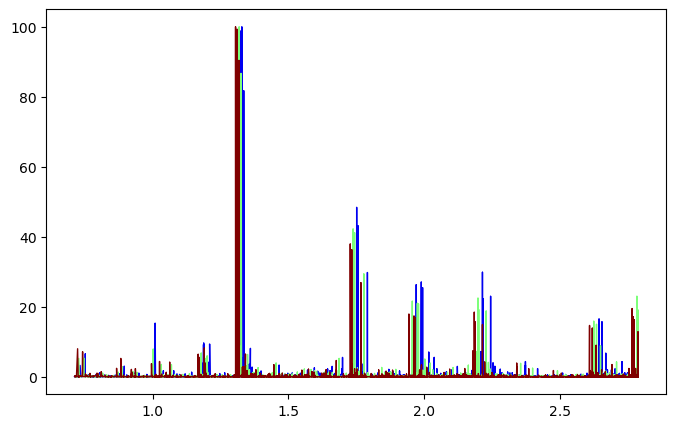

In [57]:
fig = plt.figure(figsize=(8,5))
i=1
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
i=5
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
i=10
x=XRD_list[i][:,0]
q=two_theta_to_q(x, 1.54059)
y=XRD_list[i][:,1]
plt.plot(q,y,label=i,linewidth=1, color=colors[i] )
#plt.xlim(1.3,1.35)
#plt.xlim(1.6,1.8)

In [106]:
trj_0 = read_lammps_trj('./structure_0.trj')
trj_0

Structure Summary
Lattice
    abc : 49.017648964 44.07758875999999 39.014675808
 angles : 89.86314876611064 89.863315049789 89.84616662041697
 volume : 84293.53655241212
      A : 49.017509481922055 0.0 0.11693651103116157
      B : 0.11809291204711175 44.07730483142831 0.1052794241476152
      C : 0.0 0.0 39.014675808
PeriodicSite: C (0.3554, 0.3522, 1.6154) [0.0072, 0.0080, 0.0414]
PeriodicSite: C (4.7047, 1.1785, 3.2739) [0.0959, 0.0267, 0.0836]
PeriodicSite: Mn2+ (4.6978, 0.4076, 0.0139) [0.0958, 0.0092, 0.0000]
PeriodicSite: N (4.2613, 1.1886, 2.2024) [0.0869, 0.0270, 0.0561]
PeriodicSite: C (2.6804, 2.0364, 9.2462) [0.0546, 0.0462, 0.2367]
PeriodicSite: C (3.4168, 0.6876, 5.5058) [0.0697, 0.0156, 0.1409]
PeriodicSite: C (5.1472, 2.7774, 5.3858) [0.1049, 0.0630, 0.1376]
PeriodicSite: Fe2+ (5.3152, 0.9975, 4.9835) [0.1084, 0.0226, 0.1273]
PeriodicSite: N (3.8604, 2.2034, 9.2229) [0.0786, 0.0500, 0.2360]
PeriodicSite: C (5.7195, 5.0904, 1.6451) [0.1164, 0.1155, 0.0415]
PeriodicSite:

In [107]:
xrd_0 = calculate_xrd(trj_0)

In [112]:
q = two_theta_to_q(xrd_0.x, 1.54059)

Text(0.5, 0, 'q')

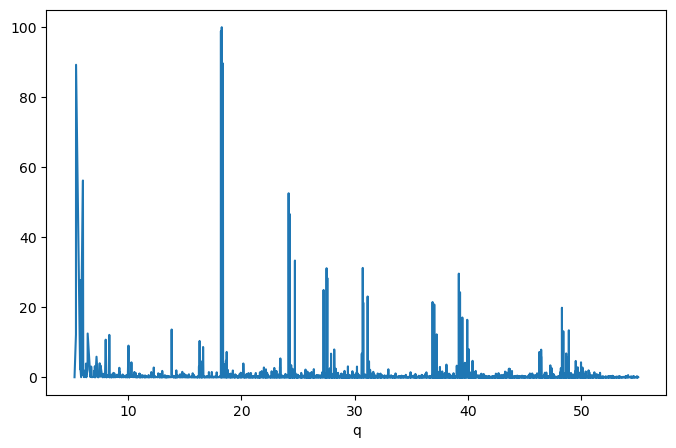

In [115]:
fig = plt.figure(figsize=(8,5))
plt.plot(xrd_0.x, xrd_0.y)
#plt.xlim(1.15,1.35)
#plt.ylim(-5,80)
plt.xlabel('q')

# PDF

In [7]:
files = os.listdir('./MD_analysis/299')

# Use a regular expression to match files that follow the POSCARn pattern
poscar_files = [f for f in files if re.match(r'POSCAR\d+', f)]
poscar_numbers = [int(re.search(r'POSCAR(\d+)', file).group(1)) for file in poscar_files]
rdf_files = [f for f in files if re.match(r'rdf_final.rdf_\d+', f)]
NaN_coor_files = [f for f in files if re.match(r'NaN_coord_final.txt_\d+', f)]
MnN_coor_files = [f for f in files if re.match(r'MnN_coord_final.txt_\d+', f)]
FeC_coor_files = [f for f in files if re.match(r'FeC_coord_final.txt_\d+', f)]

In [ ]:
path = './MD_analysis/299/'
files = os.listdir(path)
poscar_files = [f for f in files if re.match(r'POSCAR\d+', f)]
poscar_numbers = [int(re.search(r'POSCAR(\d+)', file).group(1)) for file in poscar_files]

for i in range(len(poscar_numbers)):
    file_path = path+f'POSCAR{poscar_numbers[i]}'  # Replace with your file path
    text_to_insert = "C Mn Fe N Na"
    insert_to_line_6(file_path, text_to_insert)

In [7]:
name = ['C-Fe','C-N','N-Mn','N-Na','Fe-Mn']
colors = ['r', 'orange', 'blue', 'green', 'c']
species = ["C", "Mn", "Fe", "N", "Na"]

In [8]:
def insert_to_line_6(file_path, text_to_insert):
    # Read the file contents
    with open(file_path, 'r') as file:
        lines = file.readlines()
    
    # Insert the text into the 6th line (index 5 since it's 0-based indexing)
    lines.insert(5, text_to_insert + '\n')
    
    # Write the modified content back to the file
    with open(file_path, 'w') as file:
        file.writelines(lines)

In [9]:
def calculate_bond_angle(A, B, C):
   
    # Convert input to NumPy arrays
    A = np.array(A)
    B = np.array(B)
    C = np.array(C)
    # Calculate vectors
    AB = B - A
    BC = C - B
    # Calculate the magnitudes of the vectors
    AB_magnitude = np.linalg.norm(AB)
    BC_magnitude = np.linalg.norm(BC[0])
    # Calculate the dot product
    dot_product = np.dot(AB, BC[0])
    # Calculate the cosine of the angle
    cos_theta = dot_product / (AB_magnitude * BC_magnitude)
    # Ensure the cosine value is within the valid range for arccos
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    # Calculate the angle in radians
    angle_radians = np.arccos(cos_theta)
    # Convert to degrees
    angle_degrees = np.degrees(angle_radians)
    return 180 - angle_degrees

/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:72: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:121: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


Error calculating angle for Mn: [-3.33107  5.46563  4.97063], N: [-3.77303  6.40159  6.78376], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Mn: [-2.46487 10.7844  10.0594 ], N: [-1.72301 12.4442   9.25718], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Mn: [10.6167    0.685497  4.80352 ], N: [10.1795   1.46947  6.69409], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [-5.17578  3.6506  -9.23219], C: [-7.03816  3.32443 -9.25732], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [1.24276 1.16865 9.71298], C: [ 1.03661  3.05746 10.2153 ], N: []. Error: index 0 is out of bounds for axis 0 with size 0
Error calculating angle for Fe: [ 9.96978  4.39516 -4.71894], C: [10.402    4.15504 -2.97802], N: []. Error: index 0 is out of bounds for axis 0 with size 0


/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:139: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


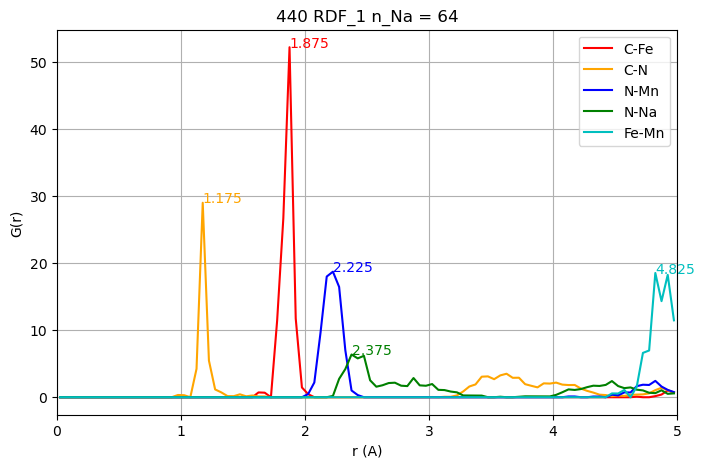

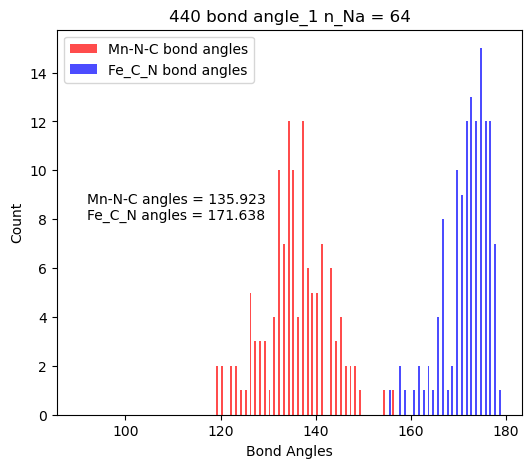

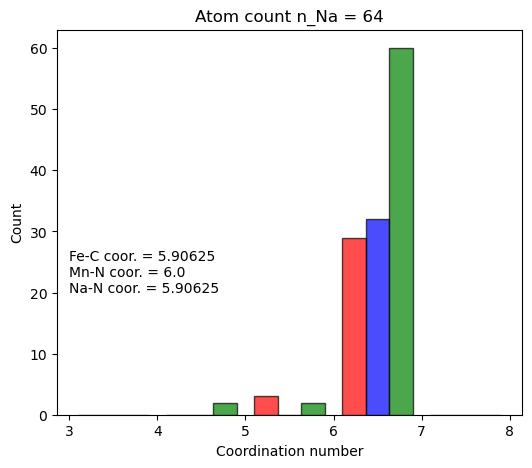

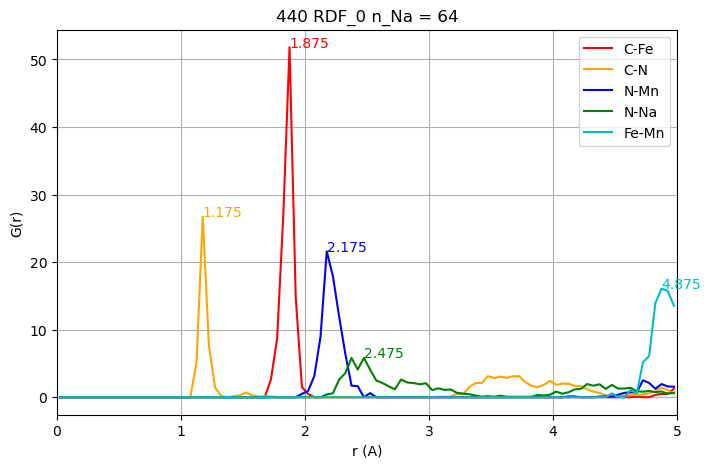

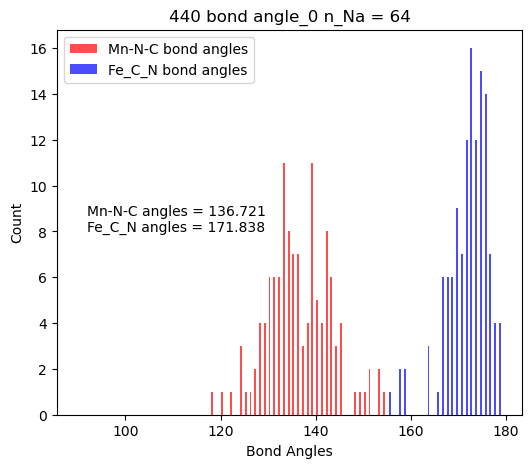

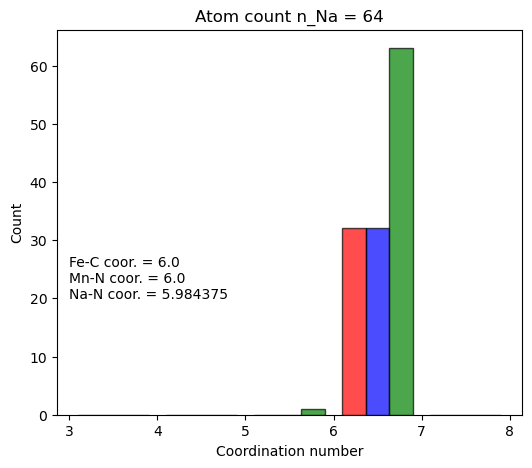

In [10]:
path = './MD_analysis/'
iteration = '440'
files = os.listdir(path+iteration)
poscar_files = [f for f in files if re.match(r'POSCAR\d+', f)]
poscar_numbers = [int(re.search(r'POSCAR(\d+)', file).group(1)) for file in poscar_files]

for i in range(len(poscar_numbers)):
    file_path = path+iteration+f'/POSCAR{poscar_numbers[i]}'  # Replace with your file path
    text_to_insert = "C Mn Fe N Na"
    insert_to_line_6(file_path, text_to_insert)

for pos_num in range(len(poscar_numbers)):
    struct = Structure.from_file(path+iteration+f'/POSCAR{poscar_numbers[pos_num]}')
    pdf = np.loadtxt(path+iteration+f'/rdf_final.rdf_{poscar_numbers[pos_num]+1}', skiprows=4)
    NaN_coor = np.loadtxt(path+iteration+f'/NaN_coord_final.txt_{poscar_numbers[i]+1}', skiprows=9)
    MnN_coor = np.loadtxt(path+iteration+f'/MnN_coord_final.txt_{poscar_numbers[i]+1}', skiprows=9)
    FeC_coor = np.loadtxt(path+iteration+f'/FeC_coord_final.txt_{poscar_numbers[i]+1}', skiprows=9)
    na_count = sum(1 for site in struct if site.species_string == "Na")

    ###### RDF ######
    r = pdf[:,1]
    fig = plt.figure(figsize=(8,5))
    for i in range(2, pdf.shape[1],2):
        j = int(i/2)
        plt.plot(r, pdf[:,i], label = name[j-1], color = colors[j-1])
        plt.text(pdf[:,1][pdf[:,i].argmax()], 
                 pdf[:,i].max(), 
                 f'{pdf[:,1][pdf[:,i].argmax()]}',
                 color = colors[j-1])
    plt.legend()
    plt.xlabel('r (A)')
    plt.xlim(0,5)
    plt.ylabel('G(r)')
    plt.grid()
    plt.title(iteration+ f' RDF_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')
    plt.savefig(path + iteration + f'/RDF_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

    ###### Bond angles #####
    from collections import Counter
    # Extract species (element types) from the sites
    species = [site.species_string for site in struct.sites]
    
    # Count the occurrences of each species
    species_counts = Counter(species)
    counts_list = []
    
    # Print the number of atoms of each type
    for element, count in species_counts.items():
        #print(f"Element: {element}, Count: {count}")
        counts_list.append(count)
        
    #1. find the coordiate of all Mn atoms
    coordinates = []
    for site in struct.sites:
        x, y, z = site.coords  # Extracting the coordinates
        coordinates.append((x, y, z))  # Append to the list 
    C_coor = np.array(coordinates[:counts_list[0]])
    Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
    Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
    N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

    #2. find the 6 closest atoms to each Mn which should be N
    distance_threshold = 3.0
    # Initialize a list to store the results
    n_within_distance = []
    # Calculate distances
    for mn in Mn_coor:
        distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)
    n_within_distance = np.array(n_within_distance)

    #3. find the closet atom to those N which should be C
    distance_threshold = 2.5
    # Initialize a list to store the results
    c_within_distance = []
    # Calculate distances
    for i in range(n_within_distance.shape[0]):
        for j in range(n_within_distance[i].shape[0]):
            n = n_within_distance[i][j]
            distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_c = C_coor[distances < distance_threshold]
            c_within_distance.append(close_c)

    #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
    Mn_N_C_angles = []
    c_index = 0
    for i in range(n_within_distance.shape[0]):
        for j in range(n_within_distance[i].shape[0]):
            Mn = Mn_coor[i]
            N = n_within_distance[i][j]
            if c_index < len(c_within_distance):
                C_n = c_within_distance[c_index]
            else:
                print(f"Warning: c_index {c_index} out of bounds, skipping...")
                continue  # Skip to the next iteration if out of bounds
            try:
                # Calculate the bond angle and append to the list
                angle = calculate_bond_angle(Mn, N, C_n)
                Mn_N_C_angles.append(angle)
            except Exception as e:
                # Handle any exceptions and continue the loop
                print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
            c_index += 1  # Increment c_index regardless of success or failure
    
    #2. find the 6 closest atoms to each Mn which should be N
    distance_threshold = 3.0
    
    # Initialize a list to store the results
    c_within_distance = []
    
    # Calculate distances
    for fe in Fe_coor:
        distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
        # Find C coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)
    
    c_within_distance = np.array(c_within_distance)

    #3. find the closet atom to those N which should be C
    
    distance_threshold = 2.5
    
    # Initialize a list to store the results
    n_within_distance = []
    
    # Calculate distances
    for i in range(c_within_distance.shape[0]):
        for j in range(c_within_distance[i].shape[0]):
            c = c_within_distance[i][j]
            distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
            # Find N coordinates within the distance threshold
            close_n = N_coor[distances < distance_threshold]
            n_within_distance.append(close_n)
    
    n_within_distance = np.array(n_within_distance)

    #4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
    Fe_C_N_angles = []
    n_index = 0
    for i in range(c_within_distance.shape[0]):
        for j in range(c_within_distance[i].shape[0]):
            Fe = Fe_coor[i]
            C = c_within_distance[i][j]
            
            # Ensure c_index is within bounds
            if n_index < len(n_within_distance):
                N_c = n_within_distance[n_index]
            else:
                print(f"Warning: c_index {n_index} out of bounds, skipping...")
                continue  # Skip to the next iteration if out of bounds
            try:
                # Calculate the bond angle and append to the list
                angle = calculate_bond_angle(Fe,C,N_c)
                Fe_C_N_angles.append(angle)
            except Exception as e:
                # Handle any exceptions and continue the loop
                print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
            
            n_index += 1  # Increment c_index regardless of success or failure

    fig = plt.figure(figsize=(6,5))
    
    bin_edges = range(90,180,1)  # bins from -10 to 20
    i=0
    # Plotting the first histogram
    counts, edges, bars = plt.hist([Mn_N_C_angles, Fe_C_N_angles], bins = bin_edges,
                                   alpha=0.7, color=['red','blue'], 
                                    label = ['Mn-N-C bond angles', 'Fe_C_N bond angles'])
    plt.text(92,8,f'Mn-N-C angles = {round(sum(Mn_N_C_angles) / len(Mn_N_C_angles),3)}\nFe_C_N angles = {round(sum(Fe_C_N_angles) / len(Fe_C_N_angles),3)}')
    plt.xlabel('Bond Angles')
    plt.ylabel('Count')
    plt.legend()
    plt.title(iteration+ f' bond angle_{poscar_numbers[pos_num]}'+f' n_Na = {na_count}')
    plt.savefig(path + iteration + f'/bond angle_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

    fig = plt.figure(figsize=(6,5))

    bin_edges = range(3,9,1)  # bins from -10 to 20
    i=0
    # Plotting the first histogram
    counts, edges, bars = plt.hist([FeC_coor[:,2],MnN_coor[:,2],NaN_coor[:,2]], bins = bin_edges,
                                   alpha=0.7, color=['red','blue','green'], 
                                   edgecolor='black', label = ['FeC_coor','MnN_coor','NaN_coor'])
    plt.text(3,20,f'Fe-C coor. = {FeC_coor[:,2].mean()}\nMn-N coor. = {MnN_coor[:,2].mean()}\nNa-N coor. = {NaN_coor[:,2].mean()}')
    plt.title(f'Atom count'+f' n_Na = {na_count}')
    plt.xlabel('Coordination number')
    plt.ylabel('Count')
    #plt.legend(frameon=False)
    
    plt.savefig(path + iteration + f'/coordination_{poscar_numbers[pos_num]}', dpi=300, bbox_inches='tight')

In [30]:
struct
na_count = sum(1 for site in struct if site.species_string == "Na")
print(f"Number of Na atoms: {na_count}")

Number of Na atoms: 60


In [22]:

print(path+iteration)

./MD_analysis/289


In [39]:
poscar_numbers

[3, 2, 1, 10, 5, 0]

In [22]:
struct.get_neighbors(

AttributeError: 'Structure' object has no attribute 'site'

In [5]:
r = pdf[:,1]

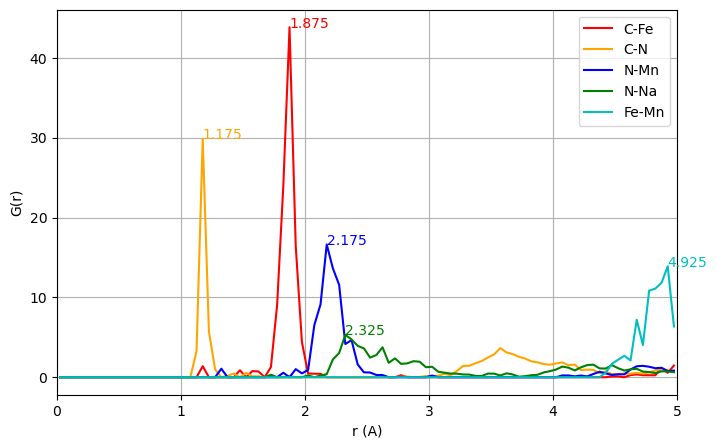

In [11]:
fig = plt.figure(figsize=(8,5))
for i in range(2, pdf.shape[1],2):
    j = int(i/2)
    plt.plot(r, pdf[:,i], label = name[j-1], color = colors[j-1])
    plt.text(pdf[:,1][pdf[:,i].argmax()], 
             pdf[:,i].max(), 
             f'{pdf[:,1][pdf[:,i].argmax()]}',
             color = colors[j-1])
plt.legend()
plt.xlabel('r (A)')
plt.xlim(0,5)
plt.ylabel('G(r)')
plt.grid()

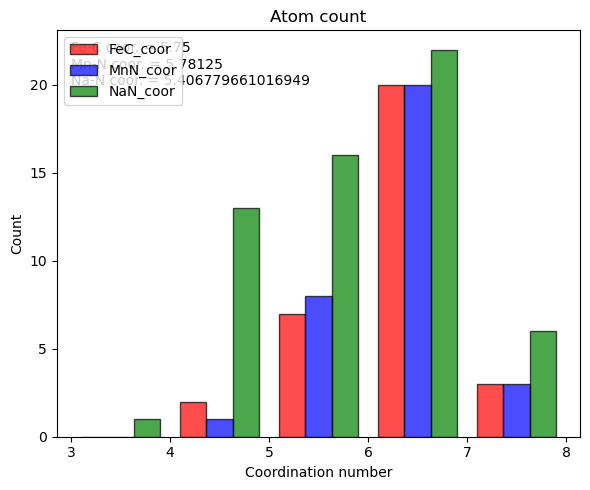

In [16]:
fig = plt.figure(figsize=(6,5))

bin_edges = range(3,9,1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([FeC_coor[:,2],MnN_coor[:,2],NaN_coor[:,2]], bins = bin_edges,
                               alpha=0.7, color=['red','blue','green'], 
                               edgecolor='black', label = ['FeC_coor','MnN_coor','NaN_coor'])
plt.text(3,20,f'Fe-C coor. = {FeC_coor[:,2].mean()}\nMn-N coor. = {MnN_coor[:,2].mean()}\nNa-N coor. = {NaN_coor[:,2].mean()}')
plt.title(f'Atom count')
plt.xlabel('Coordination number')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()

# Bond angles

In [174]:
def calculate_bond_angle(A, B, C):
   
    # Convert input to NumPy arrays
    A = np.array(A)
    B = np.array(B)
    C = np.array(C)
    # Calculate vectors
    AB = B - A
    BC = C - B
    # Calculate the magnitudes of the vectors
    AB_magnitude = np.linalg.norm(AB)
    BC_magnitude = np.linalg.norm(BC[0])
    # Calculate the dot product
    dot_product = np.dot(AB, BC[0])
    # Calculate the cosine of the angle
    cos_theta = dot_product / (AB_magnitude * BC_magnitude)
    # Ensure the cosine value is within the valid range for arccos
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    # Calculate the angle in radians
    angle_radians = np.arccos(cos_theta)
    # Convert to degrees
    angle_degrees = np.degrees(angle_radians)
    return 180 - angle_degrees

In [5]:
from pymatgen.core import Structure, Lattice
struct = Structure.from_file("POSCAR0")

In [26]:
from collections import Counter
# Extract species (element types) from the sites
species = [site.species_string for site in struct.sites]

# Count the occurrences of each species
species_counts = Counter(species)
counts_list = []

# Print the number of atoms of each type
for element, count in species_counts.items():
    print(f"Element: {element}, Count: {count}")
    counts_list.append(count)

Element: H, Count: 189
Element: He, Count: 32
Element: Li, Count: 32
Element: Be, Count: 192
Element: B, Count: 65


## Compute the Mn-N-C bond angles

1. find the coordiate of all Mn atoms
2. find the 6 closest atoms to each Mn which should be N
3. find the closet atom to those N which should be C
4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram

In [51]:
#1. find the coordiate of all Mn atoms
coordinates = []
for site in struct.sites:
    x, y, z = site.coords  # Extracting the coordinates
    coordinates.append((x, y, z))  # Append to the list

C_coor = np.array(coordinates[:counts_list[0]])
Mn_coor = np.array(coordinates[counts_list[0]:counts_list[0]+counts_list[1]])
Fe_coor = np.array(coordinates[counts_list[0]+counts_list[1]:counts_list[0]+counts_list[1]+counts_list[2]])
N_coor = np.array(coordinates[counts_list[0]+counts_list[1]+counts_list[2]:])

In [183]:
#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0

# Initialize a list to store the results
n_within_distance = []

# Calculate distances
for mn in Mn_coor:
    distances = np.linalg.norm(N_coor - mn, axis=1)  # Compute distances from the current Mn
    # Find N coordinates within the distance threshold
    close_n = N_coor[distances < distance_threshold]
    n_within_distance.append(close_n)
    
n_within_distance = np.array(n_within_distance)

# Print the results
for i, close_n in enumerate(n_within_distance):
    print(f"Mn atom {i + 1} is close to the following N atoms:")
    for n in close_n:
        print(f"  N coordinates: {n}")

Mn atom 1 is close to the following N atoms:
  N coordinates: [-12.2223   -3.09263  -8.86907]
  N coordinates: [-9.24645 -1.93534 -9.13614]
  N coordinates: [-11.5434    -0.375231  -7.64459 ]
Mn atom 2 is close to the following N atoms:
  N coordinates: [-6.55198 -2.67922 -4.16798]
  N coordinates: [-7.55687e+00  1.65906e-04 -5.62950e+00]
  N coordinates: [-5.88801   0.186758 -2.79051 ]
  N coordinates: [-4.58957 -1.4886  -6.47061]
  N coordinates: [-3.75622 -1.74127 -3.64213]
  N coordinates: [-4.59336  1.12678 -5.27338]
Mn atom 3 is close to the following N atoms:
  N coordinates: [-9.27847 -1.20939 -2.10192]
  N coordinates: [-7.82439  -1.1971    0.815704]
  N coordinates: [-10.5076    -2.38474    0.900203]
  N coordinates: [-11.8183      0.0826028  -0.475105 ]
  N coordinates: [-8.99961   1.64259  -0.707436]
  N coordinates: [-10.08     0.5935   1.9408]
Mn atom 4 is close to the following N atoms:
  N coordinates: [-5.26015 -1.68631  5.5854 ]
  N coordinates: [-6.38232  1.15664  4.

/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:13: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  del sys.path[0]


In [184]:
num = []
for i in range(n_within_distance.shape[0]):
    num.append(n_within_distance[i].shape[0])
    
def cumulative_sum(lst):
    cum_sum = []
    current_sum = 0
    for value in lst:
        current_sum += value
        cum_sum.append(current_sum)
    return cum_sum

cum_sum = cumulative_sum(num)

In [185]:
#3. find the closet atom to those N which should be C

distance_threshold = 2

# Initialize a list to store the results
c_within_distance = []

# Calculate distances
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        n = n_within_distance[i][j]
        distances = np.linalg.norm(C_coor - n, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_c = C_coor[distances < distance_threshold]
        c_within_distance.append(close_c)

# Print the results
for i, close_c in enumerate(c_within_distance):
    print(f"N atom {i + 1} is close to the following C atoms:")
    for c in close_c:
        print(f"  C coordinates: {c}")

N atom 1 is close to the following C atoms:
  C coordinates: [-12.1615   -4.26288  -9.0925 ]
N atom 2 is close to the following C atoms:
  C coordinates: [-8.12471 -1.63808 -9.44839]
N atom 3 is close to the following C atoms:
  C coordinates: [-11.0412    -0.603158  -6.61173 ]
N atom 4 is close to the following C atoms:
  C coordinates: [-6.18417 -4.18101 -4.15077]
N atom 5 is close to the following C atoms:
  C coordinates: [-8.60347  -0.520097 -5.49691 ]
N atom 6 is close to the following C atoms:
  C coordinates: [-5.49163  -0.022136 -1.69382 ]
N atom 7 is close to the following C atoms:
  C coordinates: [-5.33409 -1.67669 -7.36651]
N atom 8 is close to the following C atoms:
  C coordinates: [-2.73572 -1.49716 -4.12587]
N atom 9 is close to the following C atoms:
  C coordinates: [-4.69908  2.3123  -5.31734]
N atom 10 is close to the following C atoms:
  C coordinates: [-9.62339 -1.31564 -3.21188]
N atom 11 is close to the following C atoms:
  C coordinates: [-6.71268  -0.865601  

In [186]:
#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Mn_N_C_angles = []
c_index = 0
for i in range(n_within_distance.shape[0]):
    for j in range(n_within_distance[i].shape[0]):
        Mn = Mn_coor[i]
        N = n_within_distance[i][j]
        
        # Ensure c_index is within bounds
        if c_index < len(c_within_distance):
            C_n = c_within_distance[c_index]
        else:
            print(f"Warning: c_index {c_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds

        print(i, j, c_index)  # Debug information
        
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Mn, N, C_n)
            Mn_N_C_angles.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Mn: {Mn}, N: {N}, C_n: {C_n}. Error: {e}")
        
        c_index += 1  # Increment c_index regardless of success or failure
    

0 0 0
0 1 1
0 2 2
1 0 3
1 1 4
1 2 5
1 3 6
1 4 7
1 5 8
2 0 9
2 1 10
2 2 11
2 3 12
2 4 13
2 5 14
3 0 15
3 1 16
3 2 17
3 3 18
3 4 19
3 5 20
4 0 21
4 1 22
4 2 23
4 3 24
4 4 25
4 5 26
5 0 27
5 1 28
5 2 29
6 0 30
6 1 31
6 2 32
6 3 33
6 4 34
6 5 35
7 0 36
7 1 37
7 2 38
7 3 39
7 4 40
7 5 41
8 0 42
8 1 43
8 2 44
9 0 45
9 1 46
9 2 47
9 3 48
9 4 49
9 5 50
10 0 51
10 1 52
10 2 53
11 0 54
11 1 55
11 2 56
12 0 57
12 1 58
12 2 59
12 3 60
12 4 61
12 5 62
13 0 63
13 1 64
13 2 65
14 0 66
14 1 67
14 2 68
14 3 69
14 4 70
14 5 71
15 0 72
15 1 73
16 0 74
16 1 75
16 2 76
17 0 77
17 1 78
17 2 79
17 3 80
Error calculating angle for Mn: [ 4.1023   -0.675198 -4.64123 ], N: [ 2.32414 -2.43851 -6.11189], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
18 0 81
18 1 82
18 2 83
18 3 84
18 4 85
18 5 86
18 6 87
Error calculating angle for Mn: [5.75129e-17 1.59033e-15 1.14816e-16], N: [-0.539919 -0.049489  0.086973], C_n: []. Error: index 0 is out of bounds for axis 0 with size 0
19 0 88
19 1 89
19 2 90


## Compute the Fe-C-N bond angles

In [202]:
#2. find the 6 closest atoms to each Mn which should be N
distance_threshold = 3.0

# Initialize a list to store the results
c_within_distance = []

# Calculate distances
for fe in Fe_coor:
    distances = np.linalg.norm(C_coor - fe, axis=1)  # Compute distances from the current Mn
    # Find C coordinates within the distance threshold
    close_c = C_coor[distances < distance_threshold]
    c_within_distance.append(close_c)

c_within_distance = np.array(c_within_distance)

# Print the results
for i, close_c in enumerate(c_within_distance):
    print(f"Fe atom {i + 1} is close to the following C atoms:")
    for c in close_c:
        print(f"  C coordinates: {c}")

Fe atom 1 is close to the following C atoms:
  C coordinates: [-10.1689   -2.7797   -5.46007]
  C coordinates: [-9.62339 -1.31564 -3.21188]
  C coordinates: [-12.0528   -1.29552  -4.31516]
  C coordinates: [-8.60347  -0.520097 -5.49691 ]
  C coordinates: [-11.0412    -0.603158  -6.61173 ]
  C coordinates: [-10.5519     0.794654  -4.38019 ]
Fe atom 2 is close to the following C atoms:
  C coordinates: [-10.732    -4.85889  -1.75847]
  C coordinates: [-8.32167  -4.92628  -0.765935]
  C coordinates: [-10.2375    -3.4656     0.506573]
Fe atom 3 is close to the following C atoms:
  C coordinates: [-5.46619 -4.57233  2.88177]
  C coordinates: [-5.08543 -3.02319  5.1627 ]
  C coordinates: [-3.17113 -4.3042   4.29514]
Fe atom 4 is close to the following C atoms:
  C coordinates: [-9.77047  3.35515 -7.74936]
  C coordinates: [-11.959     3.01807  -9.18392]
  C coordinates: [-10.5421    5.3873   -9.03909]
Fe atom 5 is close to the following C atoms:
  C coordinates: [-6.71268  -0.865601  0.59247

/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:14: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  


In [203]:
#3. find the closet atom to those N which should be C

distance_threshold = 2

# Initialize a list to store the results
n_within_distance = []

# Calculate distances
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        c = c_within_distance[i][j]
        distances = np.linalg.norm(N_coor - c, axis=1)  # Compute distances from the current Mn
        # Find N coordinates within the distance threshold
        close_n = N_coor[distances < distance_threshold]
        n_within_distance.append(close_n)

n_within_distance = np.array(n_within_distance)

# Print the results
for i, close_n in enumerate(n_within_distance):
    print(f"C atom {i + 1} is close to the following N atoms:")
    for n in close_n:
        print(f"  N coordinates: {n}")

C atom 1 is close to the following N atoms:
  N coordinates: [-10.256    -3.89426  -5.7907 ]
C atom 2 is close to the following N atoms:
  N coordinates: [-9.27847 -1.20939 -2.10192]
C atom 3 is close to the following N atoms:
  N coordinates: [-13.1953   -1.52806  -4.15501]
C atom 4 is close to the following N atoms:
  N coordinates: [-7.55687e+00  1.65906e-04 -5.62950e+00]
C atom 5 is close to the following N atoms:
  N coordinates: [-11.5434    -0.375231  -7.64459 ]
C atom 6 is close to the following N atoms:
  N coordinates: [-10.6226    1.90605  -4.00068]
C atom 7 is close to the following N atoms:
  N coordinates: [-11.2177   -4.75506  -2.83793]
C atom 8 is close to the following N atoms:
  N coordinates: [-7.31435 -4.80612 -1.36542]
C atom 9 is close to the following N atoms:
  N coordinates: [-10.5076    -2.38474    0.900203]
C atom 10 is close to the following N atoms:
  N coordinates: [-5.87485 -4.6609   1.79467]
C atom 11 is close to the following N atoms:
  N coordinates: [

/home/yy276937/.conda/envs/py37/lib/python3.7/site-packages/ipykernel_launcher.py:17: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  app.launch_new_instance()


In [205]:
#4. use the coordinate of Mn, C, N to compute the bond angles and plot a histogram
Fe_C_N_angles = []
n_index = 0
for i in range(c_within_distance.shape[0]):
    for j in range(c_within_distance[i].shape[0]):
        Fe = Fe_coor[i]
        C = c_within_distance[i][j]
        
        # Ensure c_index is within bounds
        if n_index < len(n_within_distance):
            N_c = n_within_distance[n_index]
        else:
            print(f"Warning: c_index {n_index} out of bounds, skipping...")
            continue  # Skip to the next iteration if out of bounds

        print(i, j, n_index)  # Debug information
        
        try:
            # Calculate the bond angle and append to the list
            angle = calculate_bond_angle(Fe,C,N_c)
            Fe_C_N_angles.append(angle)
        except Exception as e:
            # Handle any exceptions and continue the loop
            print(f"Error calculating angle for Fe: {Fe}, C: {C}, N: {N_c}. Error: {e}")
        
        n_index += 1  # Increment c_index regardless of success or failure
    

0 0 0
0 1 1
0 2 2
0 3 3
0 4 4
0 5 5
1 0 6
1 1 7
1 2 8
2 0 9
2 1 10
2 2 11
3 0 12
3 1 13
3 2 14
4 0 15
4 1 16
4 2 17
4 3 18
4 4 19
4 5 20
5 0 21
5 1 22
5 2 23
5 3 24
5 4 25
5 5 26
6 0 27
6 1 28
6 2 29
7 0 30
7 1 31
7 2 32
7 3 33
7 4 34
7 5 35
8 0 36
8 1 37
8 2 38
8 3 39
8 4 40
8 5 41
9 0 42
9 1 43
9 2 44
9 3 45
9 4 46
9 5 47
10 0 48
10 1 49
10 2 50
10 3 51
10 4 52
10 5 53
11 0 54
11 1 55
11 2 56
11 3 57
11 4 58
11 5 59
12 0 60
13 0 61
13 1 62
13 2 63
14 0 64
14 1 65
14 2 66
14 3 67
14 4 68
14 5 69
15 0 70
15 1 71
16 0 72
16 1 73
16 2 74
16 3 75
16 4 76
16 5 77
17 0 78
17 1 79
17 2 80
18 0 81
18 1 82
19 0 83
19 1 84
19 2 85
19 3 86
19 4 87
19 5 88
20 0 89
20 1 90
20 2 91
21 0 92
21 1 93
22 0 94
22 1 95
22 2 96
22 3 97
22 4 98
22 5 99
23 0 100
23 1 101
23 2 102
23 3 103
23 4 104
23 5 105
24 0 106
24 1 107
24 2 108
25 0 109
25 1 110
25 2 111
26 0 112
26 1 113
27 0 114
27 1 115
28 0 116
28 1 117
28 2 118
29 0 119
Error calculating angle for Fe: [5.93179  9.42682  0.267353], C: [6.4797  9.45

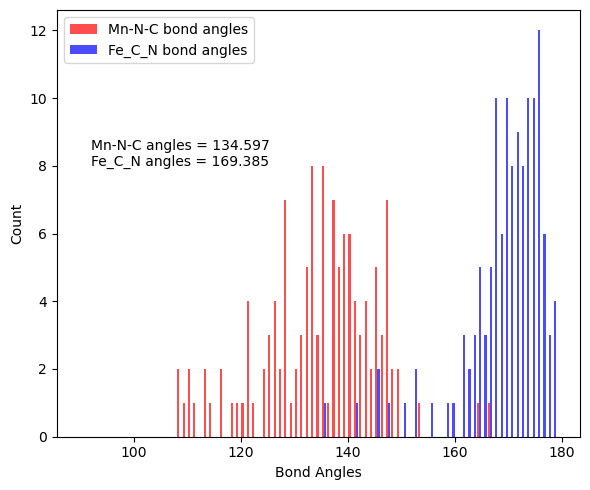

In [211]:
fig = plt.figure(figsize=(6,5))

bin_edges = range(90,180,1)  # bins from -10 to 20
i=0
# Plotting the first histogram
counts, edges, bars = plt.hist([Mn_N_C_angles, Fe_C_N_angles], bins = bin_edges,
                               alpha=0.7, color=['red','blue'], 
                                label = ['Mn-N-C bond angles', 'Fe_C_N bond angles'])
plt.text(92,8,f'Mn-N-C angles = {round(sum(Mn_N_C_angles) / len(Mn_N_C_angles),3)}\nFe_C_N angles = {round(sum(Fe_C_N_angles) / len(Fe_C_N_angles),3)}')
plt.xlabel('Bond Angles')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()